# تمرین سری سوم درس پردازش تصویر
## Image Enhancement in the Spatial Domain

- **نام و نام خانوادگی:** Amin Maki (Maky)
- **شماره دانشجویی:** 405551014


In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import time  # For measuring execution time in subsequent phases

In [6]:
# Image directory path based on your directory structure
base_dir = "Pic"
image_names = ['img1.jpg', 'img2.jpg', 'img3.jpg', 'img4.jpg', 'img5.jpg', 'img6.png', 'img7.jpg']

# Dictionary for easy access to images (with keys from img1 to img7)
images = {}

print(f"{'Image Name':<10} | {'Shape (H, W)':<14} | {'Dtype':<8} | {'Min':<5} | {'Max':<5} | {'Mean':<10}")
print("-" * 65)

for img_name in image_names:
    img_path = os.path.join(base_dir, img_name)
    # Read image in grayscale mode
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    
    if img is None:
        print(f"Error: Could not load {img_name} from {img_path}")
        continue
        
    key_name = img_name.split('.')[0]
    images[key_name] = img
    
    # Extract features according to instructions
    img_shape = str(img.shape)
    img_dtype = str(img.dtype)
    img_min = np.min(img)
    img_max = np.max(img)
    img_mean = np.mean(img)
    
    print(f"{key_name:<10} | {img_shape:<14} | {img_dtype:<8} | {img_min:<5} | {img_max:<5} | {img_mean:<10.2f}")


Image Name | Shape (H, W)   | Dtype    | Min   | Max   | Mean      
-----------------------------------------------------------------
img1       | (278, 182)     | uint8    | 0     | 255   | 50.07     
img2       | (486, 640)     | uint8    | 0     | 240   | 64.77     
img3       | (265, 397)     | uint8    | 0     | 244   | 50.19     
img4       | (413, 521)     | uint8    | 0     | 255   | 133.69    
img5       | (371, 493)     | uint8    | 0     | 255   | 99.14     
img6       | (315, 318)     | uint8    | 92    | 139   | 107.42    
img7       | (512, 512)     | uint8    | 36    | 241   | 111.64    


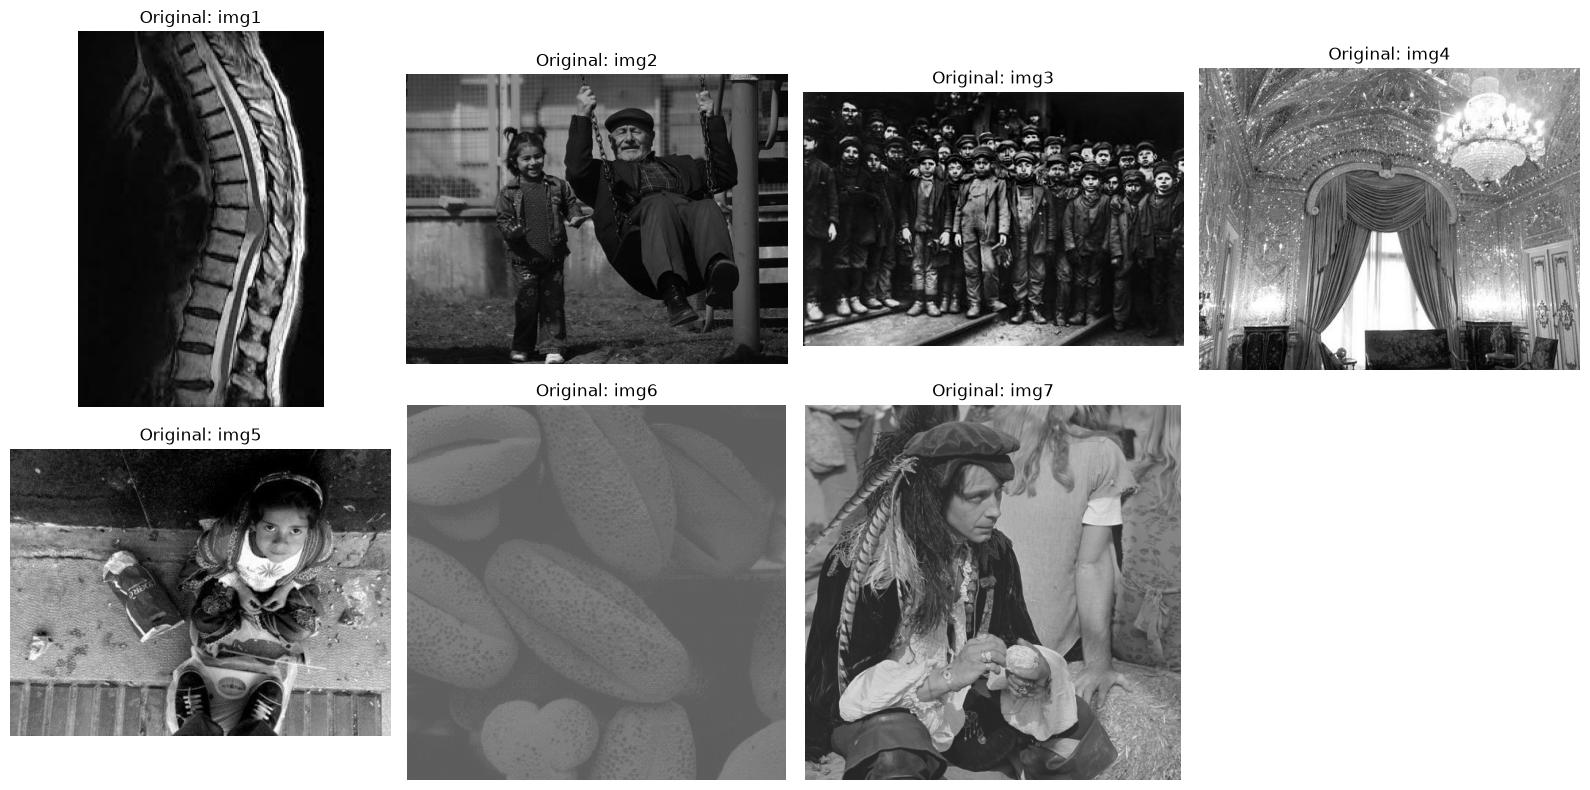

In [7]:
# Plot all images together to verify correct loading
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, (name, img) in enumerate(images.items()):
    axes[i].imshow(img, cmap='gray', vmin=0, vmax=255)
    axes[i].set_title(f"Original: {name}")
    axes[i].axis('off')

# Hide the last empty axis (since we have 7 images)
axes[7].axis('off')

plt.tight_layout()
plt.show()


In [ ]:
def apply_transformation(img, func_type, n=None):
    """
    Apply point-wise transformations on the image
    """
    img_float = img.astype(np.float64) / 255.0
    
    if func_type == 'negative':
        res = 1.0 - img_float
    elif func_type == 'log':
        c = 1.0 / np.log(1 + 1.0) # Simplification
        res = c * np.log(1 + img_float)
    elif func_type == 'inverse_log':
        res = np.exp(img_float) - 1
    elif func_type == 'power':
        res = np.power(img_float, n)
    elif func_type == 'root':
        res = np.power(img_float, 1/n)
    elif func_type == 'identity':
        res = img_float
        
    # Scale back to 0-255 range and convert to uint8
    res = np.clip(res * 255, 0, 255).astype(np.uint8)
    return res


In [ ]:
# List of transformations and corresponding images according to the table
tasks = [
    ('img1', ['negative', 'log']),
    ('img3', ['root', 'identity']),  # For root, test n = [2, 4, 6, 10]
    ('img4', ['power', 'inverse_log'])  # For power, test n = [2, 4, 6, 10]
]

# Helper function for side-by-side comparison
def plot_transform(original, transformed, title):
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].imshow(original, cmap='gray', vmin=0, vmax=255)
    ax[0].set_title("Original")
    ax[1].imshow(transformed, cmap='gray', vmin=0, vmax=255)
    ax[1].set_title(title)
    plt.show()

# Run a test for img1 (Negative)
neg_img1 = apply_transformation(images['img1'], 'negative')
plot_transform(images['img1'], neg_img1, "Negative img1")

# Now apply this structure to the remaining images and add a loop for n = [2, 4, 6, 10]
